<a href="https://colab.research.google.com/github/Crayon897/miami-dade-311-analysis/blob/main/311_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Which Miami-Dade ZIP Codes Wait Longest for Pothole Repairs?
An analysis of 2023 Miami-Dade 311 service requests.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/311_2023.csv')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,ticket_id,issue_type,issue_description,case_owner,case_owner_description,street_address,city,state,zip_code,neighborhood_district,...,sr_xcoordinate,sr_ycoordinate,latitude,longitude,method_received,sr_priority,goal_days,actual_completed_days,ticket_year,ObjectId
0,23-10000374,BULKY TRASH REQUEST BY APPOINTMENT,NaN,Solid_Waste_Management,Solid Waste Management,21122 SW 92ND CT,Town_of_Cutler_Bay,Florida,33189.0,District 8,...,873554.351,450424.639,25.571308,-80.340525,WEB,STANDARD,8.0,11.0,2023,1
1,23-10000376,BREEDER / PET STORE FOLLOW-UP,NaN,Enforcement_Section-3-36,Enforcement Section,9690 NW 41ST ST,City_of_Doral,Florida,33178.0,District 12,...,869217.668,537584.781,25.811171,-80.352385,INHOUSE,STANDARD,180.0,1.0,2023,2
2,23-10000377,INJURED ANIMAL,NaN,Enforcement_Section-3-36,Enforcement Section,NW 142ND LN & NW 87TH AVE,City_of_Miami_Lakes,Florida,33018.0,District 13,...,872951.375,570986.622,25.903017,-80.340527,INHOUSE,EMERGNCY,180.0,0.0,2023,3
3,23-10000378,BULKY TRASH REQUEST BY APPOINTMENT,NaN,Solid_Waste_Management,Solid Waste Management,10380 SW 66TH TER,Miami_Dade_County,Florida,33173.0,District 10,...,866149.750,499350.780,25.706020,-80.362272,WEB,STANDARD,8.0,28.0,2023,4
4,23-10000379,ILLEGAL DUMPING / LITTER,NaN,COM_SW,COM Solid Waste,1656 SW 6TH ST,City_of_Miami,Florida,33135.0,District 5,...,912160.747,521835.219,25.767201,-80.222142,IPHONE,STANDARD,7.0,16.0,2023,5


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343851 entries, 0 to 343850
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   ticket_id                      343851 non-null  object 
 1   issue_type                     343851 non-null  object 
 2   issue_description              0 non-null       float64
 3   case_owner                     343851 non-null  object 
 4   case_owner_description         343851 non-null  object 
 5   street_address                 343451 non-null  object 
 6   city                           343379 non-null  object 
 7   state                          343449 non-null  object 
 8   zip_code                       343449 non-null  float64
 9   neighborhood_district          343851 non-null  object 
 10  created_year_month             343851 non-null  int64  
 11  ticket_created_date_time       343851 non-null  object 
 12  ticket__last_update_date_time 

In [10]:
df['issue_type'].value_counts().head(15)

,count
issue_type,
BULKY TRASH REQUEST BY APPOINTMENT,100851
GREEN WASTE CART REQUEST,49908
MOSQUITO INSPECTION REQUEST,18369
RECYCLING BLUE CART ISSUES,15950
BULKY TRASH COMPLAINT,12165
POTHOLE,10984
ILLEGAL DUMPING - WM,10453
PET ACCOUNT UPDATE,9342
GARBAGE COMPLAINT,9058


In [11]:
df['ticket_status'].value_counts()

,count
ticket_status,
CLOSED,311740
CANCEL,16439
LOCKED,8930
DUP,4532
WIP,1314
LIEN,516
OPEN,380


In [12]:
df['created'] = pd.to_datetime(df['ticket_created_date_time'], errors='coerce', utc=True)
df['closed'] = pd.to_datetime(df['ticket_closed_date_time'], errors='coerce', utc=True)
print('Created dates that failed:', df['created'].isna().sum())
print('Closed dates missing:', df['closed'].isna().sum())

df['response_days'] = (df['closed'] - df['created']).dt.total_seconds() / 86400
df['response_days'].describe()

Created dates that failed: 0
Closed dates missing: 10711


,response_days
count,333140.000000
mean,10.817698
std,22.013618
min,-0.852083
25%,1.445139
50%,7.322569
75%,12.101389
max,513.605556


In [13]:
start = len(df)

clean = df.dropna(subset=['created', 'closed', 'zip_code'])
print('Removed for missing dates or ZIP:', start - len(clean))

before = len(clean)
clean = clean[clean['response_days'] >= 0].copy()
print('Removed for closing before opening:', before - len(clean))

before = len(clean)
clean = clean[clean['ticket_status'] == 'CLOSED'].copy()
print('Removed for not being truly closed:', before - len(clean))

clean['zip_code'] = clean['zip_code'].astype(int).astype(str)
print('Rows left:', len(clean))

Removed for missing dates or ZIP: 11081
Removed for closing before opening: 4109
Removed for not being truly closed: 21386
Rows left: 307275


In [14]:
for t in ['POTHOLE', 'ILLEGAL DUMPING - WM', 'ILLEGAL DUMPING / LITTER']:
    s = clean[clean['issue_type'] == t]
    print(t, ':', len(s), 'requests across', s['zip_code'].nunique(), 'ZIP codes')

POTHOLE : 5030 requests across 70 ZIP codes
ILLEGAL DUMPING - WM : 5356 requests across 60 ZIP codes
ILLEGAL DUMPING / LITTER : 3247 requests across 21 ZIP codes


In [15]:
ISSUE = 'POTHOLE'

subset = clean[clean['issue_type'] == ISSUE]
print(ISSUE, ':', len(subset), 'requests')
print('Median days to close:', round(subset['response_days'].median(), 1))

POTHOLE : 5030 requests
Median days to close: 4.3


In [16]:
subset[['response_days', 'actual_completed_days', 'goal_days']].head(10)

,response_days,actual_completed_days,goal_days
150,71.305556,72.0,3.0
193,32.152083,33.0,3.0
226,1.318750,1.0,3.0
274,3.587500,4.0,3.0
276,16.584722,17.0,3.0
280,72.528472,73.0,3.0
291,72.495139,73.0,3.0
299,71.470833,72.0,3.0
310,1.409722,2.0,3.0
317,2.402778,3.0,3.0


In [17]:
df[df['issue_type'] == 'POTHOLE']['ticket_status'].value_counts()

,count
ticket_status,
CLOSED,8139
LOCKED,1525
DUP,990
CANCEL,330


In [18]:
pot = df[(df['issue_type'] == 'POTHOLE') & (df['ticket_status'] == 'CLOSED')]
print('Closed potholes:', len(pot))
print('Missing ZIP:', pot['zip_code'].isna().sum())
print('Missing close date:', pot['closed'].isna().sum())
print('Closed before opened:', (pot['response_days'] < 0).sum())

Closed potholes: 8139
Missing ZIP: 0
Missing close date: 0
Closed before opened: 3109


In [19]:
neg = pot[pot['response_days'] < 0]
print('How "closed before opened" potholes were reported:')
print(neg['method_received'].value_counts().head(), '\n')

z = subset[subset['zip_code'] == '33034']
print('How ZIP 33034 potholes were reported:')
print(z['method_received'].value_counts().head())

How "closed before opened" potholes were reported:
method_received
XTERFACE    3047
PHONE         47
WEB           10
IPHONE         2
EMAIL          2
Name: count, dtype: int64 

How ZIP 33034 potholes were reported:
method_received
PHONE      43
WEB        42
IPHONE     24
ANDROID     2
Name: count, dtype: int64


In [20]:
subset = subset.copy()
subset['met_goal'] = subset['response_days'] <= subset['goal_days']

by_zip = subset.groupby('zip_code').agg(
    requests=('response_days', 'count'),
    median_days=('response_days', 'median'),
    pct_met_goal=('met_goal', 'mean'),
)
by_zip['median_days'] = by_zip['median_days'].round(1)
by_zip['pct_met_goal'] = (by_zip['pct_met_goal'] * 100).round()

print('ZIP codes:', len(by_zip))
by_zip = by_zip[by_zip['requests'] >= 30]
print('ZIP codes with 30+ requests:', len(by_zip))

by_zip = by_zip.sort_values('median_days', ascending=False)
by_zip.head(10)

ZIP codes: 70
ZIP codes with 30+ requests: 36


,requests,median_days,pct_met_goal
zip_code,,,
33167,78,8.0,28.0
33179,58,7.0,24.0
33168,42,6.9,31.0
33183,126,6.5,29.0
33142,133,6.4,34.0
33177,202,5.7,44.0
33166,51,5.6,25.0
33015,67,5.6,31.0
33143,72,5.5,39.0


In [21]:
by_zip.tail(10)

,requests,median_days,pct_met_goal
zip_code,,,
33157,132,3.4,47.0
33162,87,3.3,49.0
33175,175,3.3,49.0
33176,164,3.0,50.0
33031,205,2.7,50.0
33030,150,2.6,53.0
33055,50,2.6,52.0
33032,322,2.5,52.0
33174,37,2.3,54.0


In [22]:
print('Goal days the county uses for potholes:', subset['goal_days'].unique())
print('Countywide median:', round(subset['response_days'].median(), 1), 'days')
print('Fixed within goal:', round(subset['met_goal'].mean() * 100), '%')
print('Slowest ZIP:', by_zip.index[0], '-', by_zip['median_days'].iloc[0], 'days')
print('Fastest ZIP:', by_zip.index[-1], '-', by_zip['median_days'].iloc[-1], 'days')

Goal days the county uses for potholes: [3.]
Countywide median: 4.3 days
Fixed within goal: 43 %
Slowest ZIP: 33167 - 8.0 days
Fastest ZIP: 33034 - 0.6 days


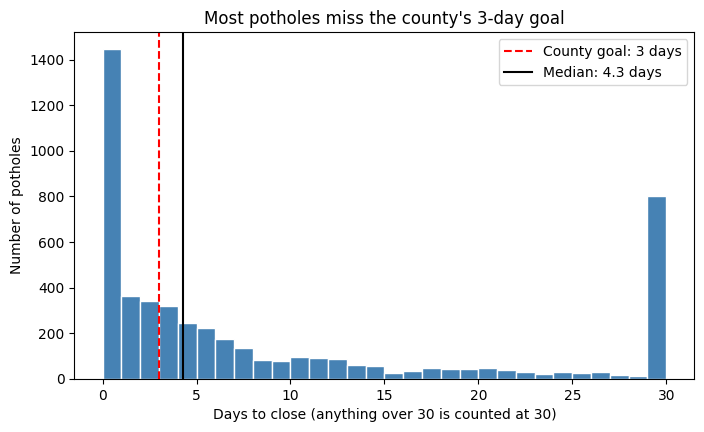

In [23]:
import matplotlib.pyplot as plt

med = subset['response_days'].median()

plt.figure(figsize=(8, 4.5))
plt.hist(subset['response_days'].clip(upper=30), bins=30, color='steelblue', edgecolor='white')
plt.axvline(3, color='red', linestyle='--', label='County goal: 3 days')
plt.axvline(med, color='black', label=f'Median: {med:.1f} days')
plt.title("Most potholes miss the county's 3-day goal")
plt.xlabel('Days to close (anything over 30 is counted at 30)')
plt.ylabel('Number of potholes')
plt.legend()
plt.savefig('chart1_response_times.png', dpi=150, bbox_inches='tight')
plt.show()

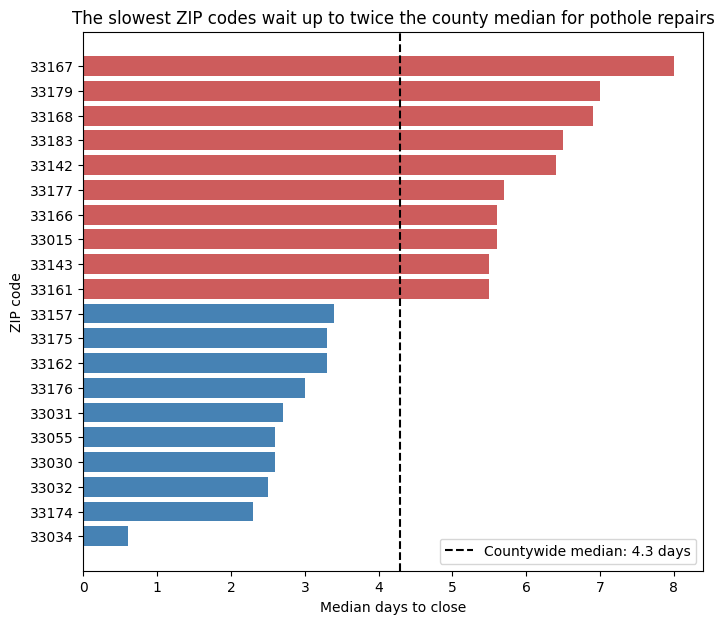

In [24]:
med = subset['response_days'].median()
chart = pd.concat([by_zip.head(10), by_zip.tail(10)]).sort_values('median_days')
colors = ['indianred' if d > med else 'steelblue' for d in chart['median_days']]

plt.figure(figsize=(8, 7))
plt.barh(chart.index, chart['median_days'], color=colors)
plt.axvline(med, color='black', linestyle='--', label=f'Countywide median: {med:.1f} days')
plt.title('The slowest ZIP codes wait up to twice the county median for pothole repairs')
plt.xlabel('Median days to close')
plt.ylabel('ZIP code')
plt.legend()
plt.savefig('chart2_zip_codes.png', dpi=150, bbox_inches='tight')
plt.show()

Correlation between requests and median days: -0.19


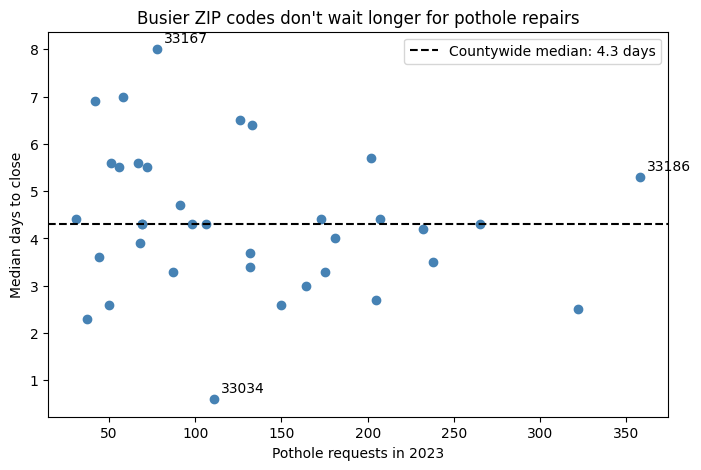

In [25]:
med = subset['response_days'].median()
r = by_zip['requests'].corr(by_zip['median_days'])
print('Correlation between requests and median days:', round(r, 2))

plt.figure(figsize=(8, 5))
plt.scatter(by_zip['requests'], by_zip['median_days'], color='steelblue')
plt.axhline(med, color='black', linestyle='--', label=f'Countywide median: {med:.1f} days')
for z in [by_zip.index[0], by_zip.index[-1], by_zip['requests'].idxmax()]:
    plt.annotate(z, (by_zip.loc[z, 'requests'], by_zip.loc[z, 'median_days']),
                 xytext=(5, 5), textcoords='offset points')
plt.title("Busier ZIP codes don't wait longer for pothole repairs")
plt.xlabel('Pothole requests in 2023')
plt.ylabel('Median days to close')
plt.legend()
plt.savefig('chart3_busy_vs_slow.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusion

**Answer:** Yes. How long a reported pothole takes to fix varies a lot by ZIP code.

- Miami-Dade's goal is to fix potholes within **3 days**, but only **43%** of the 5,030 pothole requests analyzed were closed within it. The countywide median was **4.3 days**.
- In ZIP **33167**, the median was **8.0 days**, nearly double the countywide median. Two ZIPs with over 120 requests each, **33183** and **33142**, took more than 6 days, so slow service isn't just a small-sample effect.
- **Busier ZIP codes weren't slower.** The correlation between request volume and median days was [your number], a weak relationship.

**Limitations**
- Only tickets marked CLOSED were included; canceled, duplicate, and locked tickets were removed.
- 3,109 closed pothole tickets were closed before they were opened and were removed. They may be repairs that crews logged after fixing them.
- Only the 36 ZIP codes with at least 30 pothole requests were compared. Smaller ZIPs show more extreme medians, so their rankings are less certain.
- ZIP 33034 (median 0.6 days) is far faster than every other ZIP and needs further investigation.
- The dataset mostly covers county-handled requests, not cities like the City of Miami or Coral Gables.
- "Closed" may not always mean the pothole was physically repaired.

**Next steps**
- Map the results to see whether slow ZIPs cluster geographically.
- Add income data by ZIP code to test whether service differs by neighborhood.
- Build a model that predicts which requests will miss the 3-day goal.